In [3]:
### my stuff ###
import sys
sys.path.append('../calculations/')
from consts import *
from functions import *
from physics_functions import *

### python stuff ###
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tk
from scipy.optimize import curve_fit
import scipy.misc as misc
import scipy.special as sp
from scipy import integrate as spInt
from scipy.interpolate import interp1d

### Notes ###

<u> Morozov 2010 </u>
* for 0.5 Bar the UV flux is 10% higher than 1bar, but visible is basically zero. 
* 1bar fluctuations in vis are statistical (minimal collection efficiency)
* main method is broadband data

***
#### things done ####
* some data was negative (from webplot digitizer?)

* multiply morozov UV by 10%

In [4]:
### loading data ###

#gern data gives a yield
gern_x, gern_y = np.loadtxt("./literature_data/gernhauser_cf4_05bar.csv", skiprows = 2, delimiter = ",", unpack = True)
# gern_x, gern_y = np.loadtxt("./literature_data/gernhauser_cf4_05bar_spikes.csv", skiprows = 2, delimiter = ",", unpack = True)
gern_x_ar, gern_y_ar = np.loadtxt("./literature_data/gernhauser_gar_05bar.csv", skiprows = 2, delimiter = ",", unpack = True)

#reorder gernhauser data
gern_x, gern_y = zip( *sorted( zip(gern_x, gern_y) ) )
#make all gernhauser data > 0
gern_y = np.array([x if x > 0 else 0 for x in gern_y])

mor_x_1bar, mor_y_1bar = np.genfromtxt("./literature_data/morozov_2010_spectrum.csv", skip_header = 2,  usecols = (0,1), delimiter = ",", unpack = True)
mor_x_5bar, mor_y_5bar = np.genfromtxt("./literature_data/morozov_2010_spectrum.csv", skip_header = 2,  usecols = (6,7), delimiter = ",", unpack = True)

#making all morozov data positivee
mor_y_1bar = np.array([x if x > 0 else 0 for x in mor_y_1bar])
mor_y_5bar = np.array([x if x > 0 else 0 for x in mor_y_5bar])

In [5]:
## scale gernhauser and morozov by the UV peak

# get index of 200 nm
igern_200 = next(x[0] for x in enumerate(gern_x) if x[1] > 200)

imor1_lastGern = next(x[0] for x in enumerate(mor_x_1bar) if x[1] > max(gern_x))
imor1_200 = next(x[0] for x in enumerate(mor_x_1bar) if x[1] > 200)
imor1_500 = next(x[0] for x in enumerate(mor_x_1bar) if x[1] > 500)

mor_y_05bar = mor_y_1bar * 1.1
scaleGernMax = float(max(mor_y_05bar[0:imor1_500])/max(gern_y[igern_200:]))

print(scaleGernMax)

0.07570706807659955


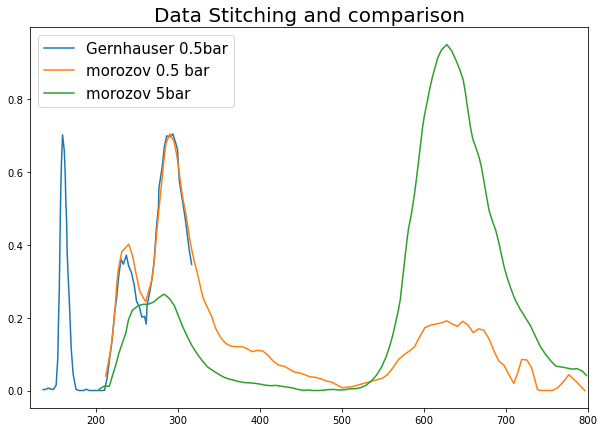

In [6]:
#simple scaling
fig, ax = plt.subplots(1, 1, figsize = (10, 7))

ax.plot(gern_x, gern_y*scaleGernMax, label = "Gernhauser 0.5bar")
# plt.plot(gern_x_ar, gern_y_ar/max(gern_y_ar))
ax.plot(mor_x_1bar, mor_y_05bar, label = "morozov 0.5 bar")
ax.plot(mor_x_5bar, mor_y_5bar, label = "morozov 5bar")

ax.set_title("Data Stitching and comparison", fontsize = 20)
ax.set_xlim(120, 800)
ax.legend(fontsize = 15)

descrip1 = """scaled Morozov UV by 10%
(1 to 0.5 bar change)
matched spectra at 300nm"""
# ax.text(320, 0.5, descrip1, fontsize = 14, bbox=dict(facecolor='blue', alpha=0.2, edgecolor = 'black'))

plt.show()

In [7]:
# correction factor to increase yield of GernHauser #
# this is ratio of areas 200nm to end (gernhauser) and 200-500 (morozov)

a_gern_200plus = spInt.trapezoid(y = gern_y[igern_200:]*scaleGernMax, x = gern_x[igern_200:])
a_mor_200tolastGern = spInt.trapezoid(y = mor_y_05bar[:imor1_lastGern], x = mor_x_1bar[:imor1_lastGern])
a_mor_200plus = spInt.trapezoid(y = mor_y_05bar[:imor1_500], x = mor_x_1bar[:imor1_500])

ratio_gernMor = a_mor_200plus/a_gern_200plus
ratio_MorMor = a_mor_200plus/a_mor_200tolastGern
print(ratio_gernMor)
print(ratio_MorMor)
corrR = (ratio_gernMor + ratio_MorMor)/2

1.5211340349602567
1.4964482171422149


***
### <center> Combining Yield </center>
<p float="left">
    <img src="literature_pics/morozov_UV_yields.png" width=400>
    <img src="literature_pics/morozov_vis_yields.png" width=400> 
</p>
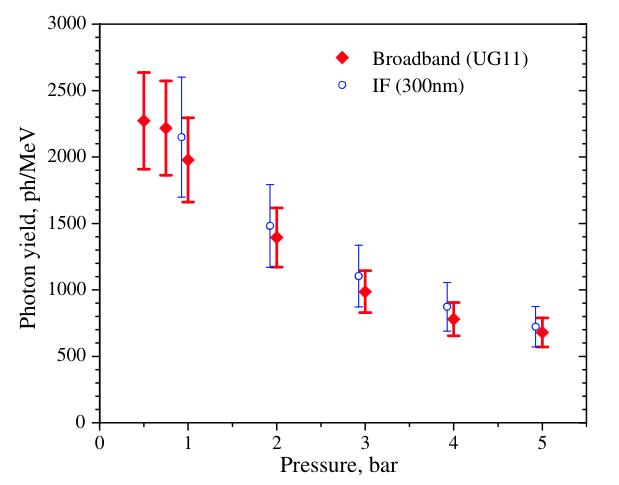

In [8]:
uv_x, uv_y, uv_ey = np.genfromtxt("./literature_data/morozov_UV_yields.csv", skip_header = 2,  usecols = (0,1, 3), delimiter = ",", unpack = True)
uv_ey = uv_ey - uv_y

vis_x, vis_y, vis_ey = np.genfromtxt("./literature_data/morozov_vis_yields.csv", skip_header = 2,  usecols = (0,1, 3), delimiter = ",", unpack = True)
vis_ey = vis_ey - vis_y

net_x = vis_x
net_y = uv_y[2:] + vis_y
net_ey = np.sqrt(uv_ey[2:]**2 + vis_ey**2)

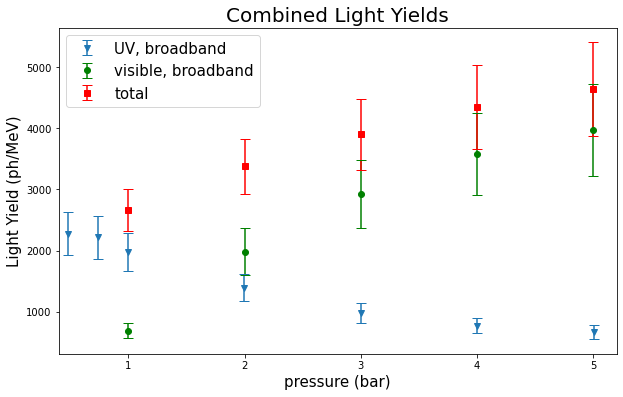

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))
font = 15

ax.errorbar(uv_x, uv_y, yerr = uv_ey, xerr = None, fmt = 'v', capsize = 5, label = "UV, broadband")
ax.errorbar(vis_x, vis_y, yerr = vis_ey, xerr = None, fmt = 'o', color = 'g', capsize = 5, label = "visible, broadband")

ax.errorbar(net_x, net_y, yerr = net_ey, fmt = 's', color = 'r', capsize = 5, label = "total")

ax.set_title("Combined Light Yields", fontsize = 20)
ax.set_ylabel("Light Yield (ph/MeV)", fontsize = font)
ax.set_xlabel("pressure (bar)", fontsize = font)

ax.set_xlim(0.4, 5.2)

ax.legend(fontsize = font)
plt.show()

#### Expected 160 nm Yield ####

* integrate gernhauser on its own
* scale morozov spectrum from 200-500 to match their UV yield at 0.5 bar
* scale up gernhauser to match this at 200
* integrate 160nm to get that yield

In [10]:
### integrating gernhauser on its own ###

yield_gern_UV = spInt.trapezoid(y = gern_y[igern_200:], x = gern_x[igern_200:], dx = 1)
yield_gern_VUV = spInt.trapezoid(y = gern_y[:igern_200], x = gern_x[:igern_200], dx = 1)

## scale Gern to match Morozov Yield
yield_UV_mor_05bar = uv_y[0]
scaleGernUV = yield_UV_mor_05bar/(yield_gern_UV*corrR)
yield_VUV_gern_scaled = yield_gern_VUV*scaleGernUV

print("Gern VUV yield = %.F ph/MeV" % yield_gern_VUV)
print("Gern VUV yield, scale UV to match Morozov = %.F ph/MeV" % yield_VUV_gern_scaled)

print("Morozov UV yield = %0.F" % yield_UV_mor_05bar)
print("Gern UV yield = %0.F ph/MeV" % yield_gern_UV)
print("Gern UV yield, scaled for full spectrum = %0.F ph/MeV" % (yield_gern_UV*corrR))

Gern VUV yield = 99 ph/MeV
Gern VUV yield, scale UV to match Morozov = 277 ph/MeV
Morozov UV yield = 2278
Gern UV yield = 539 ph/MeV
Gern UV yield, scaled for full spectrum = 813 ph/MeV


#### full yield ####
* adding scaled Gern values to morozov total yields

2555.540233949301


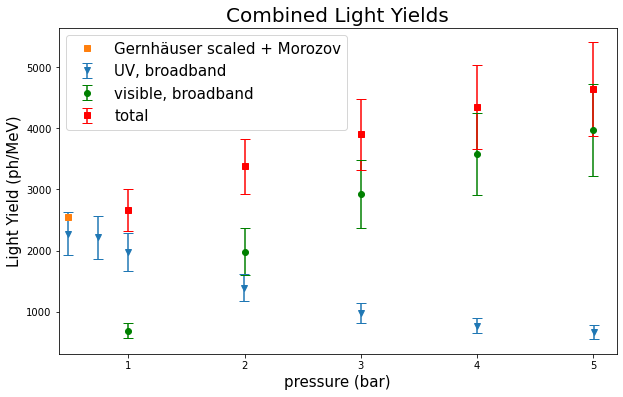

In [15]:

fig, ax = plt.subplots(1, 1, figsize = (10, 6))
font = 15

ax.errorbar(uv_x, uv_y, yerr = uv_ey, xerr = None, fmt = 'v', capsize = 5, label = "UV, broadband")
ax.errorbar(vis_x, vis_y, yerr = vis_ey, xerr = None, fmt = 'o', color = 'g', capsize = 5, label = "visible, broadband")

ax.errorbar(net_x, net_y, yerr = net_ey, fmt = 's', color = 'r', capsize = 5, label = "total")

ax.plot(uv_x[0], yield_VUV_gern_scaled + uv_y[0], 's', label = "Gernhäuser scaled + Morozov")
print(yield_VUV_gern_scaled + uv_y[0])

ax.set_title("Combined Light Yields", fontsize = 20)
ax.set_ylabel("Light Yield (ph/MeV)", fontsize = font)
ax.set_xlabel("pressure (bar)", fontsize = font)

ax.set_xlim(0.4, 5.2)

ax.legend(fontsize = font)
plt.savefig("total_yields.png")

plt.show()
